<a href="https://colab.research.google.com/github/jyeon6273/DeepNeuralNetworks/blob/main/lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Character-level LSTM on Tiny Shakespeare

A small LSTM language model trained to predict the **next character** of
Shakespeare's plays, one character at a time. After training, it can be
sampled from to generate new Shakespeare-flavored text.

## What this notebook does

1. **Data** — downloads Karpathy's `tinyshakespeare.txt` (~1.1M chars) and
   builds a char-level vocabulary (~65 symbols). The text is encoded as a
   long tensor of indices and split 90/10 into train/val.
2. **Windowing** — a `CharDataset` chops the stream into non-overlapping
   windows of length `SEQ_LEN=100`; for each window the target is the same
   window shifted by one position (classic teacher-forced LM objective).
3. **Model (`CharLSTM`)** — Embedding → 2-layer `nn.LSTM` (hidden 256,
   dropout 0.2 between layers) → Dropout → Linear head over the vocab.
4. **Training** — Adam + cross-entropy over every timestep, 20 epochs, with
   train/val loss plotted at the end.
5. **Generation** — autoregressive sampling with a temperature knob, feeding
   the model its own output char-by-char to produce new text.

## Why an LSTM?

Characters carry very little information individually, so the model needs
to remember context from dozens of steps back to form words, line breaks,
and speaker tags. LSTMs' gated cell state is the classical fit for that
range of dependency, and the task is small enough that a 2-layer LSTM
trains comfortably on CPU.


In [ ]:
from pathlib import Path
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
print('imported')

imported


In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print('Device:', DEVICE)

Device: mps


In [ ]:
BATCH_SIZE = 64
SEQ_LEN = 100
STRIDE = SEQ_LEN          # non-overlapping training windows

EMBED_SIZE = 128
HIDDEN_SIZE = 256
NUM_LAYERS = 2
DROPOUT = 0.2             # applied between LSTM layers

LEARNING_RATE = 0.002
EPOCHS = 20

TEMPERATURE = 0.8

torch.manual_seed(42)

In [ ]:
URL = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

DATA_PATH = Path("tinyshakespeare.txt")

if not DATA_PATH.exists():
    print("Downloading dataset...")
    response = requests.get(URL, timeout=30)
    response.raise_for_status()
    DATA_PATH.write_text(response.text, encoding="utf-8")

text = DATA_PATH.read_text(encoding="utf-8")

print("Number of characters:", len(text))

Number of characters: 1115394


In [ ]:
print(text[200:500])

 know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [ ]:
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

print('Vocab size :', vocab_size)
print('Chars: ', "".join(chars))

Vocab size : 65
Chars:  
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


In [ ]:
def encode(s):
    return [stoi[c] for c in s]

def decode(indices):
    return "".join(itos[i] for i in indices)

print(encode('ROMEO'))
print(decode(encode('ROMEO')))

[30, 27, 25, 17, 27]
ROMEO


In [ ]:
data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.9 * len(data))
train_data = data[:split]
val_data = data[split:]

print("Encoded data shape:", tuple(data.shape))
print("Train characters:", len(train_data))
print("Validation characters:", len(val_data))

Encoded data shape: (1115394,)
Train characters: 1003854
Validation characters: 111540


In [ ]:
class CharDataset(Dataset):

    def __init__(self, data, seq_len, stride):
        self.data = data
        self.seq_len = seq_len
        self.stride = stride
        self.n_samples = (len(data) - seq_len - 1) // stride + 1

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        start = idx * self.stride
        x = self.data[start:start + self.seq_len]
        y = self.data[start + 1:start + self.seq_len + 1]
        return x, y

In [ ]:
train_dataset = CharDataset(train_data, SEQ_LEN, STRIDE)
val_dataset = CharDataset(val_data, SEQ_LEN, STRIDE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 156
Validation batches: 17


In [ ]:
x_batch, y_batch = next(iter(train_loader))

print("x:", tuple(x_batch.shape))
print("y:", tuple(y_batch.shape))
print("\ninput :", repr(decode(x_batch[0, :40].tolist())))
print("target:", repr(decode(y_batch[0, :40].tolist())))

x: (64, 100)
y: (64, 100)

input : ' the demigod Authority\nMake us pay down '
target: 'the demigod Authority\nMake us pay down f'


In [ ]:
class CharLSTM(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, num_layers, dropout):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.embedding = nn.Embedding(vocab_size, embed_size)

        self.lstm = nn.LSTM(
            input_size = embed_size,
            hidden_size = hidden_size,
            num_layers = num_layers,
            batch_first = True,
            dropout = dropout if num_layers > 1 else 0.0,
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden = None):
        x = self.embedding(x)
        output, hidden = self.lstm(x, hidden)
        output = self.dropout(output)
        logits = self.fc(output)
        return logits, hidden

    def init_hidden(self, batch_size, device):
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device = device)
        c0 = torch.zeros(self.num_layers, batch_size, self.hidden_size, device = device)

        return h0, c0

In [ ]:
model = CharLSTM(
    vocab_size = vocab_size,
    embed_size = EMBED_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT,
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())

print(model)

print(total_params)


CharLSTM(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=65, bias=True)
)
946625


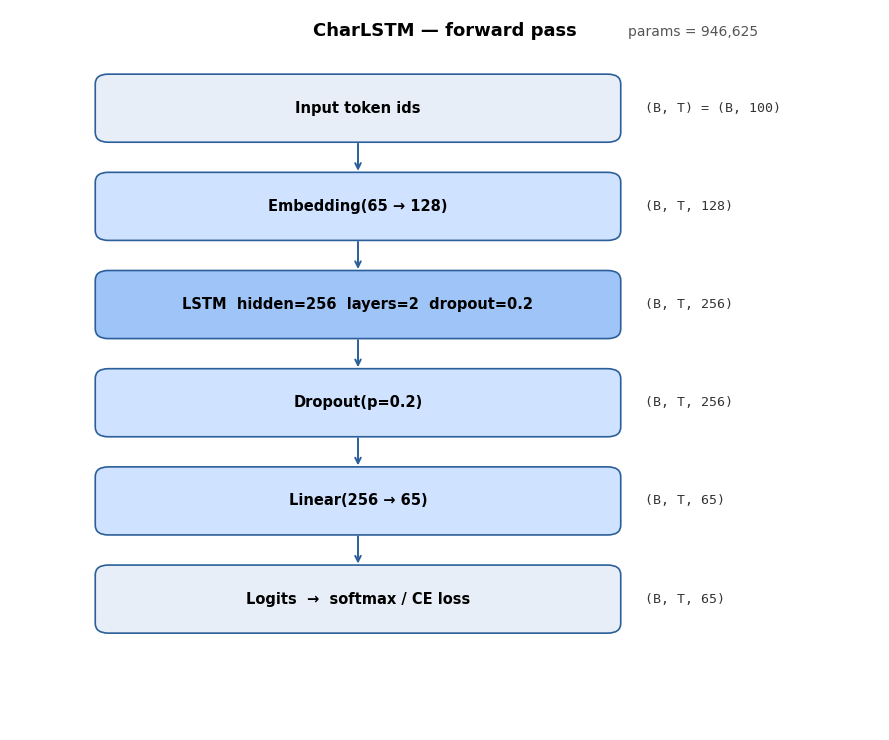

In [ ]:
# Architecture diagram
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.set_xlim(0, 10); ax.set_ylim(0, 11); ax.axis('off')

layers = [
    ('Input token ids',                f'(B, T) = (B, {SEQ_LEN})',   '#E8EEF7'),
    (f'Embedding({vocab_size} → {EMBED_SIZE})',
                                        f'(B, T, {EMBED_SIZE})',     '#CFE2FF'),
    (f'LSTM  hidden={HIDDEN_SIZE}  layers={NUM_LAYERS}  dropout={DROPOUT}',
                                        f'(B, T, {HIDDEN_SIZE})',    '#9FC5F8'),
    (f'Dropout(p={DROPOUT})',           f'(B, T, {HIDDEN_SIZE})',    '#CFE2FF'),
    (f'Linear({HIDDEN_SIZE} → {vocab_size})',
                                        f'(B, T, {vocab_size})',     '#CFE2FF'),
    ('Logits  →  softmax / CE loss',    f'(B, T, {vocab_size})',     '#E8EEF7'),
]

box_h = 1.0
y = 10.0
for label, shape, color in layers:
    ax.add_patch(mpatches.FancyBboxPatch(
        (1.0, y - box_h), 6.0, box_h,
        boxstyle='round,pad=0.02,rounding_size=0.15',
        linewidth=1.2, edgecolor='#2b5f99', facecolor=color))
    ax.text(4.0, y - box_h/2, label, ha='center', va='center',
            fontsize=10.5, weight='bold')
    ax.text(7.3, y - box_h/2, shape, ha='left', va='center',
            fontsize=9.5, family='monospace', color='#333')
    y -= 1.5

for i in range(len(layers) - 1):
    y_top = 10.0 - (i + 1) * 1.5 + 0.5
    ax.annotate('', xy=(4.0, y_top - 0.5), xytext=(4.0, y_top),
                arrowprops=dict(arrowstyle='->', lw=1.4, color='#2b5f99'))

ax.text(5.0, 10.6, 'CharLSTM — forward pass', ha='center',
        fontsize=13, weight='bold')
ax.text(8.6, 10.6, f'params = {sum(p.numel() for p in model.parameters()):,}',
        ha='right', fontsize=10, color='#555')

plt.tight_layout()
plt.show()


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = LEARNING_RATE)


In [ ]:
def train_one_epoch():
    model.train()
    total_loss = 0.0

    for x, y in train_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, vocab_size), y.reshape(-1))
        loss.backward()

        # gates keep gradients much healthier than a vanilla RNN,
        # but clipping is still cheap insurance
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(train_loader)

In [ ]:
@torch.no_grad()
def evaluate():
    model.eval()
    total_loss = 0.0

    for x, y in val_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, vocab_size), y.reshape(-1))

        total_loss += loss.item()

    return total_loss / len(val_loader)


In [ ]:
train_losses = []
val_losses = []

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch()
    val_loss = evaluate()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f}"
    )

Epoch [01/20] | Train Loss: 2.2223 | Val Loss: 1.8826
Epoch [02/20] | Train Loss: 1.7115 | Val Loss: 1.7440
Epoch [03/20] | Train Loss: 1.5937 | Val Loss: 1.6796
Epoch [04/20] | Train Loss: 1.5363 | Val Loss: 1.6449
Epoch [05/20] | Train Loss: 1.5000 | Val Loss: 1.6245
Epoch [06/20] | Train Loss: 1.4748 | Val Loss: 1.6083
Epoch [07/20] | Train Loss: 1.4565 | Val Loss: 1.5984
Epoch [08/20] | Train Loss: 1.4402 | Val Loss: 1.5907
Epoch [09/20] | Train Loss: 1.4282 | Val Loss: 1.5893
Epoch [10/20] | Train Loss: 1.4181 | Val Loss: 1.5783
Epoch [11/20] | Train Loss: 1.4095 | Val Loss: 1.5805
Epoch [12/20] | Train Loss: 1.4017 | Val Loss: 1.5699
Epoch [13/20] | Train Loss: 1.3957 | Val Loss: 1.5686
Epoch [14/20] | Train Loss: 1.3890 | Val Loss: 1.5684
Epoch [15/20] | Train Loss: 1.3844 | Val Loss: 1.5637
Epoch [16/20] | Train Loss: 1.3802 | Val Loss: 1.5665
Epoch [17/20] | Train Loss: 1.3760 | Val Loss: 1.5641
Epoch [18/20] | Train Loss: 1.3720 | Val Loss: 1.5625
Epoch [19/20] | Train Loss: 

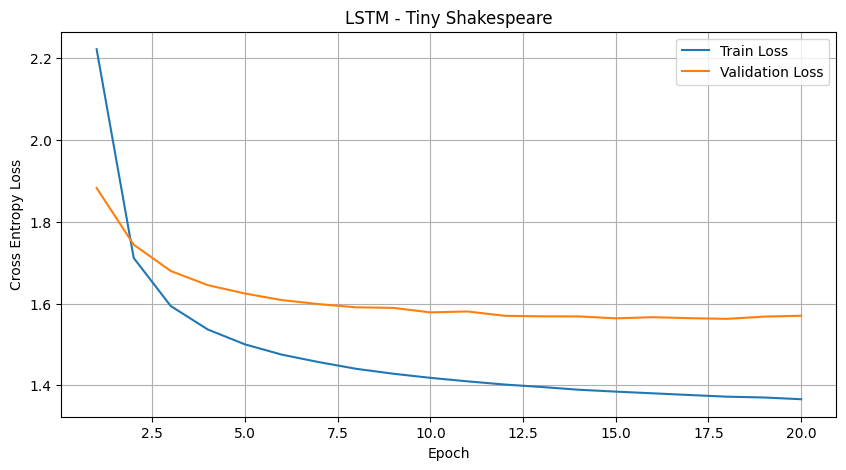

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss")
plt.plot(range(1, EPOCHS + 1), val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("LSTM - Tiny Shakespeare")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
@torch.no_grad()
def generate_text(prompt, max_new_tokens=500, temperature=0.8):
    model.eval()

    input_ids = torch.tensor(
        encode(prompt), dtype=torch.long, device=DEVICE
    ).unsqueeze(0)   # [1, seq_len]

    hidden = model.init_hidden(batch_size=1, device=DEVICE)

    # warm the states up on the prompt, then feed one character at a time
    if input_ids.shape[1] > 1:
        _, hidden = model(input_ids[:, :-1], hidden)

    current = input_ids[:, -1:]
    generated = prompt

    for _ in range(max_new_tokens):
        logits, hidden = model(current, hidden)

        logits = logits[:, -1, :] / temperature
        probabilities = F.softmax(logits, dim=-1)

        next_char = torch.multinomial(probabilities, num_samples=1)

        generated += itos[next_char.item()]
        current = next_char

    return generated

In [ ]:
print(generate_text("good ", max_new_tokens=5, temperature=TEMPERATURE))

good that Angelo I do ore.

ROMEO:
I do she would more sea,
And there's thy fair anger state of this--

AUTOLYCUS:
What is the people, not in our ancient woe,
That I do change you death to offent a castle,


In [ ]:
SEED = "ROMEO:\n"
for t in (0.2, 0.5, 0.8, 1.0, 1.5):
    torch.manual_seed(0)                 # same randomness every time
    print(f"----- temperature {t} -----")
    print(generate_text(SEED, max_new_tokens=100, temperature=t))

----- temperature 0.2 -----
ROMEO:
The man many things that we have made him the prisoner.
The proper and the princely hath for the fat
----- temperature 0.5 -----
ROMEO:
Then, he was the cause of his and the heart, and be neared
Here will more here in the filling true m
----- temperature 0.8 -----
ROMEO:
Then, here's the cause: or the churding
When my wood't and the provest fringer.
O, the idle and my m
----- temperature 1.0 -----
ROMEO:
So move more at his has, go, heremandine! I'll Hend,'teredom!
O rook more needfly to soil, say to wa
----- temperature 1.5 -----
ROMEO:
So amapel noble shathy:, go, hence hin yarm'd! Heyountened?
If provetelesd erquly to soil, sa' to wa


In [ ]:
checkpoint_path = "lstm_shakespeare.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "stoi": stoi,
        "itos": itos,
        "vocab_size": vocab_size,
        "embed_size": EMBED_SIZE,
        "hidden_size": HIDDEN_SIZE,
        "num_layers": NUM_LAYERS,
        "dropout": DROPOUT,
    },
    checkpoint_path,
)

print("Model saved to:", checkpoint_path)

Model saved to: lstm_shakespeare.pt
